    Age  Income  CreditScore  LoanAmount Employment    LoanStatus
0    25   50000          700       10000         No  not approved
1    30   60000          720       12000        Yes      approved
2    35   70000          740       14000        Yes      approved
3    40   80000          760       16000        Yes      approved
4    45   90000          780       18000        Yes      approved
5    50  100000          800       18000        Yes      approved
6    55  110000          820       17000         No  not approved
7    60  120000          840       14000        Yes      approved
8    65  130000          860       13000        Yes      approved
9    22   40000          650       20000         No  not approved
10   28   50000          780       21000        Yes      approved
11   32   60000          670       22000         No  not approved
12   38   70000          890       23000        Yes      approved
13   42   31000          900       24000         No  not approved
14   48  6

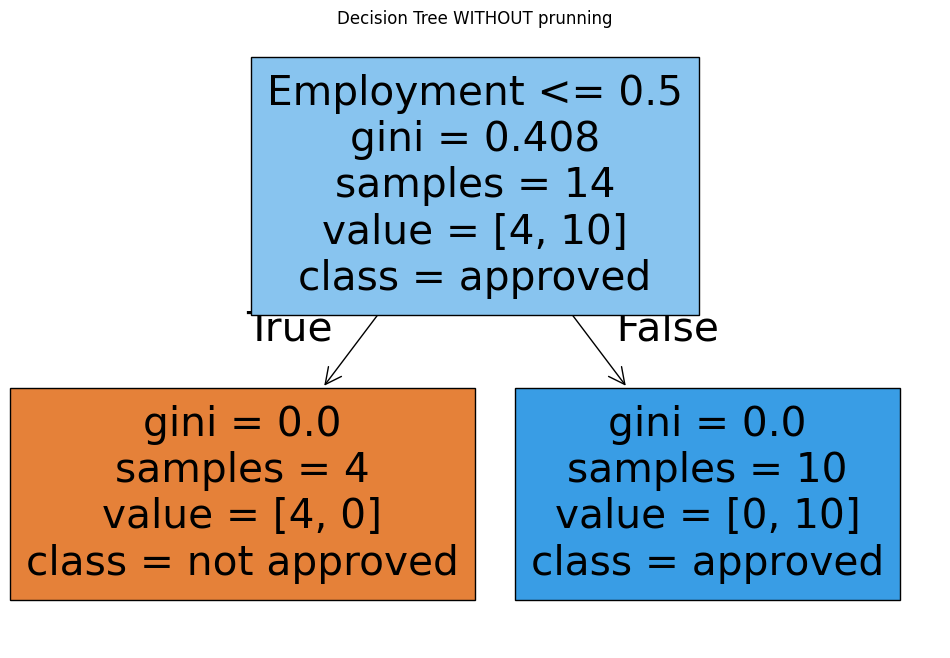


Accuracy WITH prunning: 1.0

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         3

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4


Feature Importance:
       Feature  Importance
4   Employment         1.0
0          Age         0.0
1       Income         0.0
2  CreditScore         0.0
3   LoanAmount         0.0


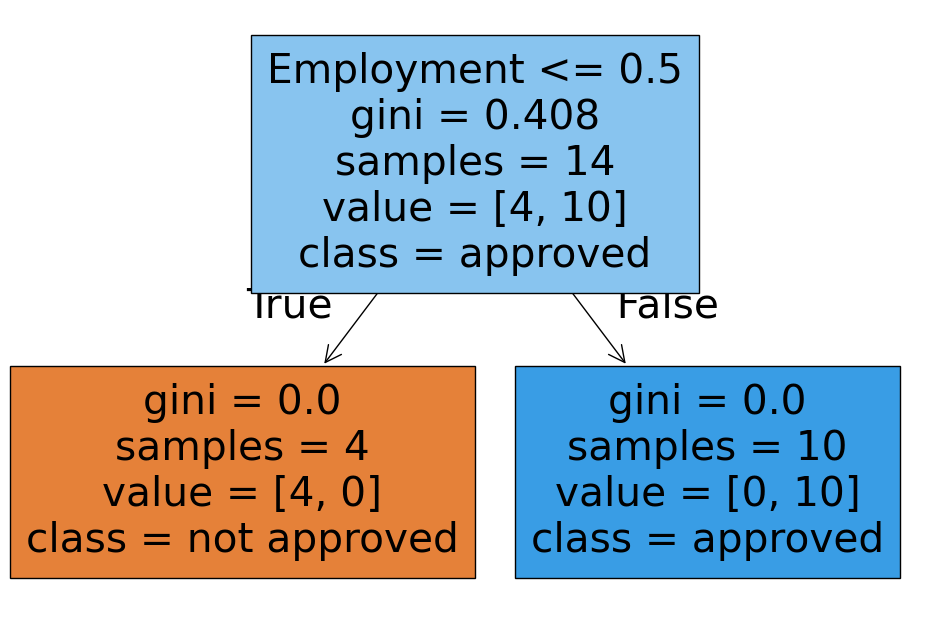

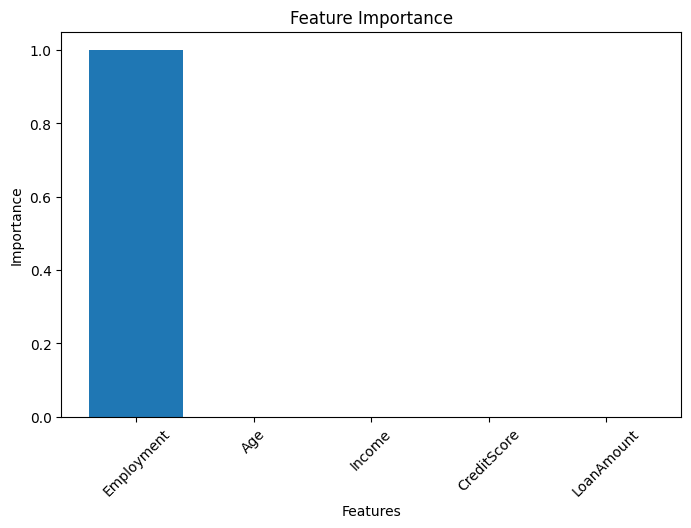

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

#---------------------------------------------------------
#1. Create Dataset
#--------------------------------------------------------

data = {

        'Age': [25, 30, 35, 40, 45, 50, 55, 60, 65,
                22, 28, 32, 38, 42, 48, 52, 56, 78],

        'Income': [50000, 60000, 70000, 80000, 90000,
                   100000, 110000, 120000, 130000,
                   40000, 50000, 60000, 70000, 31000,
                   670000, 89000, 90000, 98000],

        'CreditScore': [700, 720, 740, 760, 780, 800, 820, 840, 860,
                        650, 780, 670, 890, 900, 789, 789, 780, 870],

        'LoanAmount' : [10000, 12000, 14000, 16000, 18000, 18000, 17000, 14000, 13000,
                        20000, 21000, 22000, 23000, 24000, 25000, 26000, 20000, 21000],

        'Employment' : ['No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'Yes',
                        'No', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes'],

        'LoanStatus' : ['not approved', 'approved', 'approved', 'approved', 'approved',
                        'approved', 'not approved', 'approved', 'approved',
                        'not approved', 'approved', 'not approved', 'approved', 'not approved',
                        'approved', 'approved', 'approved', 'approved']
}


df = pd.DataFrame(data)
print(df)


#---------------------------------------------------------
# 2.Covert Categorical variable into numeric
#--------------------------------------------------------

df['Employment'] = df['Employment'].map({'No': 0, 'Yes': 1})
df['LoanStatus'] = df['LoanStatus'].map({'not approved': 0, 'approved': 1})

#---------------------------------------------------------
# 3.Seperate Input and Output
#--------------------------------------------------------

X = df.drop('LoanStatus', axis=1)
y = df['LoanStatus']

#---------------------------------------------------------
# 4.Split Dataset
#--------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
  )

#---------------------------------------------------------
# 5.Decision Tree without prunning
#---------------------------------------------------------

model_full = DecisionTreeClassifier(
    criterion= 'gini',
    random_state=42
)

model_full.fit(X_train, y_train)

y_pred_full = model_full.predict(X_test)

print()
accuracy_full = accuracy_score(y_test, y_pred_full)
print("Accuracy WITHOUT prunning:", accuracy_full)

#------------------------------------------------------
# 6.Visualize tree WITHOUT pruning
#-----------------------------------------------------
plt.figure(figsize=(12, 8))

plot_tree(
    model_full,
    feature_names=X.columns,
    class_names=['not approved','approved'],
    filled=True
)

plt.title("Decision Tree WITHOUT prunning")
plt.show()

#------------------------------------------------------
# 7.Decision Tree WITH pruning
#-----------------------------------------------------

model_pruned = DecisionTreeClassifier(
    criterion = 'gini',
    max_depth = 3,
    random_state=42
)

model_pruned.fit(X_train, y_train)

y_pred_pruned = model_pruned.predict(X_test)

print()
accuracy_pruned = accuracy_score(y_test, y_pred_pruned)
print("Accuracy WITH prunning:", accuracy_pruned)

#------------------------------------------------------
# 8.Visualize pruned tree
#-----------------------------------------------------
plt.figure(figsize=(12, 8))

plot_tree(
    model_pruned,
    feature_names=X.columns,
    class_names=['not approved','approved'],
    filled=True
)

#------------------------------------------------------
# 9.Classification report
#-----------------------------------------------------

print()
print(classification_report(y_test, y_pred_pruned))

#------------------------------------------------------
# 10.Feature Importance
#-----------------------------------------------------

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model_pruned.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print()
print("Feature Importance:")
print(importance)

#------------------------------------------------------
# 11. Feature Importance Graph
#-----------------------------------------------------

plt.figure(figsize=(8,5))
plt.bar(importance['Feature'], importance['Importance'])
plt.xlabel('Features')
plt.ylabel('Importance')
plt.title('Feature Importance')
plt.xticks(rotation=45)
plt.show()